# RAGF-BERT v5 - one model, layer-level techniques (no ensemble)

**Colab:** `Runtime -> Change runtime type -> T4 GPU`, `Run all`, upload `sarcasm_balanced_9600_full.csv` when asked.

**Single `bert-base-uncased` model.** No ensemble. The notebook trains the *same* model with different **layer-level treatments** and compares them on the same split, over several seeds:

| Variant | What it does to the BERT layers |
|---|---|
| Full fine-tuning | plain baseline, no rationale loss |
| Attention supervision | paper-style: last-layer [CLS] attention is trained toward the human rationale (lambda = 1.0) |
| + LLRD | layer-wise learning-rate decay: lower layers move less than upper layers |
| + re-init top 2 | re-initialise the top 2 encoder layers (they are the most task-specific) |
| + weighted layer pooling | classify from a learned mix of the [CLS] vectors of the last 4 layers |
| + multi-sample dropout | 5 dropout masks on the classifier head, averaged |
| + gradual unfreezing | train top 4 layers first, then 8, then all |
| + static freeze 3 | bottom 3 layers frozen for the whole run |
| RAGF-BERT | attention supervision + dynamic gradient-guided layer freezing |
| COMBO | LLRD + re-init + weighted pooling + multi-sample dropout |

**Selection rule:** the best variant is chosen by mean **validation** macro-F1 only; the test set is read once for reporting. A paired t-test over seeds shows whether a variant really beats the attention-supervision baseline. Fixes from v4 are kept (rationale loaded from `hate_rationale_weights`, `paper_split`, clean 3/3 extra posts, span IOU-F1).

**Be aware:** none of these techniques is guaranteed to help. The notebook reports the result either way.

**v6 addition - full paper comparison.** Section 9b now prints **all eight paper metrics** (accuracy, macro-F1, AUROC, IOU-F1, token-F1, AUPRC, comprehensiveness, sufficiency) for the paper baseline, the paper's proposed method, and ours (baseline, attention supervision, gradual unfreezing, and the validation-selected variant), plus the difference to the paper and a chart. Set `PAPER_COMPARISON_ONLY = True` in section 9 to run only those three variants (faster; use 5 seeds). Files written: `final_vs_paper_all_metrics.csv`, `delta_vs_paper_proposed.csv`, `paper_vs_ours_all_metrics.png`.


## 0. Experimental protocol

The notebook first checks whether valid human token-level rationales are available.

- With gold rationales: run full fine-tuning, static freezing, adaptive classification, adaptive rationale, and dual-objective RAGF-BERT.
- Without gold rationales: run full fine-tuning, static freezing, and adaptive classification; skip rationale-supervised runs without crashing. Generate illustrative model-based token explanations, but do not claim rationale plausibility improvements.

All methods use the same train/validation/test split. Results are measured on the held-out test set. Published paper scores are shown separately as contextual references, not as a matched baseline.


In [1]:
# Google Colab dependency setup — compatible with the current Colab Hugging Face stack.
# IMPORTANT:
# - Do not upgrade pip/setuptools blindly.
# - Do not install the old datasets/accelerate pins; this notebook does not use them.
# - Keep Colab's preinstalled PyTorch/CUDA untouched.
#
# Colab's current Transformers 5.x stack requires:
#   huggingface-hub >=1.31,<3
#   tokenizers >=0.23.1,<0.24
# We pin a mutually compatible set and request wheels only (no Rust compilation).

!python -m pip install -q --only-binary=:all: \
    "setuptools<82" "jedi>=0.16" \
    "huggingface-hub>=1.31,<3" \
    "tokenizers>=0.23.1,<0.24" \
    "transformers==5.21.0" \
    scikit-learn pandas numpy matplotlib seaborn

# Verify versions and imports. Restart runtime if Colab asks you to.
import sys, torch, transformers, tokenizers, huggingface_hub
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("CUDA available:", torch.cuda.is_available())


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
Transformers: 5.21.0
Tokenizers: 0.23.3
Hugging Face Hub: 1.33.0
CUDA available: True


In [2]:
import os, re, gc, json, math, random, glob, copy, warnings, hashlib, time
from dataclasses import dataclass
from typing import List, Dict, Optional, Tuple
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, roc_auc_score, precision_recall_curve,
                             auc)
import matplotlib.pyplot as plt
import seaborn as sns

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0), torch.cuda.get_device_properties(0).total_memory/1024**3, "GB")

Device: cuda
Tesla T4 14.56317138671875 GB


## 1. Configuration and Colab paths

The next cells look in `/content` and Google Drive. You can upload files when prompted, or mount Drive and set the paths below. The notebook accepts your sarcasm CSV without requiring HateXplain to be present.


In [3]:
# ---- Google Colab configuration ----
import os, glob

# Optional: mount Google Drive if your datasets are stored there.
USE_GOOGLE_DRIVE = False
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

# If your files are in Drive, put their exact paths here.
USER_CSV_PATH = ""       # e.g. "/content/drive/MyDrive/data/sarcasm_balanced_9600.csv"
HATEXPLAIN_PATHS = []    # e.g. ["/content/drive/MyDrive/HateXplain/train.json", ...]

# Model/training configuration
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 128
BATCH_SIZE = 16
EPOCHS = 4
WARMUP_FRACTION = 0.10
LR = 3e-5
WEIGHT_DECAY = 0.01
DROPOUT = 0.1
SEED = 42
NUM_WORKERS = 2
GRAD_ACCUM_STEPS = 1
MAX_GRAD_NORM = 1.0

# Dynamic policy settings (tune only on validation, never test)
MONITOR_EVERY_STEPS = 100
MIN_WARMUP_STEPS = 100
EMA_BETA = 0.8
FREEZE_PATIENCE = 3
UNFREEZE_PATIENCE = 2
FREEZE_QUANTILE = 0.20
UNFREEZE_IMPORTANCE_MULTIPLIER = 1.5
MIN_TRAINABLE_ENCODER_LAYERS = 4
MAX_FROZEN_ENCODER_LAYERS = 8
RAGF_MODE = "both"   # "both", "classification", "rationale", "none"
STATIC_FREEZE_BOTTOM = 0  # 0, 3, or 6 for static baselines

LAMBDA_RATIONALE = 1.0      # v4: was 0.001 (too small to have any effect)
LABEL_SMOOTHING = 0.0
RATIONALE_COLUMNS_CANDIDATES = [
    "rationale", "rationales", "sarcasm_rationale",
    "hate_rationale", "explanation"
]
# ---- v4 additions ----
SARCASM_RATIONALE_WEIGHT = 0.5   # rationale target = hate weight + 0.5 x sarcasm mask (as in the paper's combined rationale)
USE_PAPER_SPLIT = True           # use the CSV's paper_split (train / validation / test)
EXTRA_AGREE = "3/3"              # keep only extra HateXplain posts with 3/3 annotator agreement (None = all)
EXTRA_PLATFORM = None            # "gab" = drop extra Twitter posts
GOLD_THR = 0.5                   # human rationale word = hate weight >= 0.5
TEXT_COL = "text"
LABEL_COL = "label"

OUTPUT_DIR = "/content/ragf_bert"
os.makedirs(OUTPUT_DIR, exist_ok=True)


In [4]:
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

## 2. Load and inspect datasets

You need at least one compatible dataset. The user's CSV is sufficient to run the classification experiments. HateXplain is optional but recommended for human-rationale supervision.

The canonical target classes are `hate`, `offensive`, and `normal`. Label mapping must be reviewed. We do not infer a distinction that the source labels do not provide.


In [5]:
# Find or upload the user's CSV and optional HateXplain files.
from pathlib import Path

def find_named_file(name, roots=("/content", "/content/drive/MyDrive")):
    for root in roots:
        if os.path.isdir(root):
            hits = glob.glob(os.path.join(root, "**", name), recursive=True)
            if hits:
                return hits[0]
    return None

if not USER_CSV_PATH or not os.path.isfile(USER_CSV_PATH):
    USER_CSV_PATH = find_named_file("*sarcasm_balanced_9600*.csv")

if USER_CSV_PATH is None:
    print("Upload your sarcasm_balanced_9600.csv now. You may also select HateXplain JSON files in the same upload dialog.")
    from google.colab import files
    uploaded = files.upload()
    uploaded_paths = [os.path.join("/content", name) for name in uploaded.keys()]
    csv_hits = [p for p in uploaded_paths if p.lower().endswith(".csv") and "sarcasm" in os.path.basename(p).lower()]
    if not csv_hits:
        csv_hits = [p for p in uploaded_paths if p.lower().endswith(".csv")]
    if csv_hits:
        USER_CSV_PATH = csv_hits[0]
    HATEXPLAIN_PATHS = HATEXPLAIN_PATHS + [
        p for p in uploaded_paths if p.lower().endswith((".json", ".jsonl"))
    ]

print("User CSV path:", USER_CSV_PATH)
if USER_CSV_PATH and os.path.isfile(USER_CSV_PATH):
    user_raw = pd.read_csv(USER_CSV_PATH)
    print("User CSV shape:", user_raw.shape)
    print("Columns:", list(user_raw.columns))
    display(user_raw.head())
    for c in user_raw.columns:
        if user_raw[c].nunique(dropna=True) < 30:
            print(c, user_raw[c].value_counts(dropna=False).head(20).to_dict())
else:
    user_raw = None
    print("No user CSV found. Upload it or set USER_CSV_PATH in the configuration cell.")


Upload your sarcasm_balanced_9600.csv now. You may also select HateXplain JSON files in the same upload dialog.


Saving sarcasm_balanced_9600_full.csv to sarcasm_balanced_9600_full.csv
User CSV path: /content/sarcasm_balanced_9600_full.csv
User CSV shape: (9600, 18)
Columns: ['post_id', 'text', 'label', 'annotator_labels', 'label_agreement', 'target_communities', 'target_communities_all', 'hate_rationale', 'hate_rationale_weights', 'sarcasm_label', 'sarcasm_rationale', 'sarcasm_rationale_mask', 'toxic', 'toxic_under_sarcasm', 'platform', 'source', 'cv_fold', 'paper_split']


,post_id,text,label,annotator_labels,label_agreement,target_communities,target_communities_all,hate_rationale,hate_rationale_weights,sarcasm_label,sarcasm_rationale,sarcasm_rationale_mask,toxic,toxic_under_sarcasm,platform,source,cv_fold,paper_split
0,13517786_gab,they used to have cracker and honky now they h...,offensive,hatespeech|offensive|offensive,2/3,African|Arab|Hispanic|Jewish,African|Arab|Hispanic|Homosexual|Islam|Jewish|...,they used to have cracker and honky ... i can ...,"[0.5, 0.5, 0.5, 0.5, 1.0, 1.0, 1.0, 0.0, 0.0, ...",sarcasm,does this mean i can say nigger faggot kike sa...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",True,True,gab,original_annotated,4,train
1,1179019319717568512_twitter,now playing on dnaradio lil duval ft ball gree...,normal,normal|normal|normal,3/3,NaN,NaN,NaN,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",non-sarcasm,NaN,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",False,False,twitter,original_annotated,2,train
2,1179075099569393666_twitter,<user> there is need for awsreness campaign to...,normal,normal|normal|normal,3/3,NaN,NaN,NaN,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",non-sarcasm,NaN,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",False,False,twitter,original_annotated,3,train
3,14049816_gab,gatewaypundit is pure fake news it just clickb...,offensive,offensive|offensive|offensive,3/3,Other,Other,retarded,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",non-sarcasm,NaN,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",True,False,gab,original_annotated,0,train
4,14537881_gab,a majority of us votes against muslim immigrat...,hatespeech,hatespeech|hatespeech|offensive,2/3,Islam|Refugee,Arab|Islam|Refugee,a majority of us votes against muslim immigrat...,"[0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.0, ...",non-sarcasm,NaN,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",True,False,gab,original_annotated,1,train


label {'offensive': 3200, 'normal': 3200, 'hatespeech': 3200}
annotator_labels {'normal|normal|normal': 1667, 'hatespeech|hatespeech|hatespeech': 1499, 'offensive|offensive|offensive': 985, 'normal|normal|offensive': 437, 'hatespeech|offensive|hatespeech': 432, 'offensive|hatespeech|hatespeech': 416, 'hatespeech|hatespeech|offensive': 406, 'offensive|normal|offensive': 399, 'normal|offensive|offensive': 396, 'offensive|normal|normal': 382, 'hatespeech|offensive|offensive': 370, 'offensive|offensive|hatespeech': 358, 'offensive|offensive|normal': 350, 'offensive|hatespeech|offensive': 342, 'normal|offensive|normal': 317, 'normal|hatespeech|hatespeech': 174, 'normal|normal|hatespeech': 145, 'hatespeech|normal|hatespeech': 145, 'hatespeech|normal|normal': 131, 'hatespeech|hatespeech|normal': 128}
label_agreement {'2/3': 5449, '3/3': 4151}
sarcasm_label {'unannotated': 6418, 'non-sarcasm': 2736, 'sarcasm': 446}
toxic {True: 6400, False: 3200}
toxic_under_sarcasm {False: 9384, True: 216}
pl

In [6]:
# Label normalization: edit only after inspecting the source label inventory.
LABEL2ID = {"hate": 0, "hatespeech": 0, "hate speech": 0,
            "offensive": 1, "offensive speech": 1,
            "normal": 2, "non-hate": 2, "non_hate": 2, "non-offensive": 2}
ID2LABEL = {0: "hate", 1: "offensive", 2: "normal"}

def normalize_label(v):
    if pd.isna(v): return None
    s = str(v).strip().lower()
    return LABEL2ID.get(s)

def normalize_sarcasm(v):
    if pd.isna(v): return None
    s = str(v).strip().lower()
    if s in {"sarcasm", "sarcastic", "1", "true", "yes"}: return 1
    if s in {"non-sarcasm", "non_sarcastic", "not sarcastic", "0", "false", "no"}: return 0
    return None

def find_rationale_column(df):
    for c in RATIONALE_COLUMNS_CANDIDATES:
        if c in df.columns: return c
    return None

user_df = None
def _arr(x):
    try: return np.asarray(json.loads(x), dtype=float) if isinstance(x, str) else None
    except Exception: return None

if user_raw is not None:
    assert TEXT_COL in user_raw.columns, f"Expected text column '{TEXT_COL}'. Found {list(user_raw.columns)}"
    assert LABEL_COL in user_raw.columns, f"Expected label column '{LABEL_COL}'. Found {list(user_raw.columns)}"
    n_rows = len(user_raw)
    texts = user_raw[TEXT_COL].fillna("").astype(str)
    hw_col = user_raw["hate_rationale_weights"] if "hate_rationale_weights" in user_raw else pd.Series([None] * n_rows)
    sm_col = user_raw["sarcasm_rationale_mask"] if "sarcasm_rationale_mask" in user_raw else pd.Series([None] * n_rows)
    rat_train, rat_gold = [], []
    for t, h_raw, s_raw in zip(texts, hw_col, sm_col):
        nw = len(t.split()); h = _arr(h_raw); sm = _arr(s_raw)
        h = h if (h is not None and len(h) == nw) else None
        sm = sm if (sm is not None and len(sm) == nw) else None
        r = np.zeros(nw)
        if h is not None: r = r + h
        if sm is not None: r = r + SARCASM_RATIONALE_WEIGHT * sm
        rat_train.append(r.tolist() if r.sum() > 0 else None)          # missing rationale = NOT available (never a negative rationale)
        rat_gold.append(h.tolist() if (h is not None and h.sum() > 0) else None)
    user_df = pd.DataFrame({
        "text": texts,
        "label": user_raw[LABEL_COL].map(normalize_label),
        "source": user_raw["source"] if "source" in user_raw else "user_sarcasm",
        "sarcasm": user_raw["sarcasm_label"].map(normalize_sarcasm) if "sarcasm_label" in user_raw else np.nan,
        "rationale_raw": rat_train,
        "gold_raw": rat_gold,
        "split": user_raw["paper_split"] if "paper_split" in user_raw else None,
        "agree": user_raw["label_agreement"] if "label_agreement" in user_raw else None,
        "platform": user_raw["platform"] if "platform" in user_raw else None,
    })
    print("Unmapped labels:", user_raw.loc[user_df.label.isna(), LABEL_COL].value_counts().to_dict())
    print("Posts with a usable rationale target:", int(user_df.rationale_raw.notna().sum()), "of", len(user_df))
    display(user_df.groupby(["source","label"], dropna=False).size())


Unmapped labels: {}
Posts with a usable rationale target: 6630 of 9600


source              label
hatexplain_added    0        2009
                    1        2757
                    2        1652
original_annotated  0        1191
                    1         443
                    2        1548
dtype: int64

### HateXplain input parser

HateXplain releases commonly store posts in JSON with `post_id`, `post_tokens`, `annotators` and `rationales`. File layouts can vary. This parser attempts the common JSON structure and prints a schema preview. Verify the resulting label/rationale mapping against the exact release you downloaded.

In [7]:
def parse_hatexplain_record(rec):
    tokens = rec.get("post_tokens", rec.get("tokens", []))
    text = rec.get("text")
    if text is None:
        text = " ".join(map(str, tokens)) if isinstance(tokens, list) else str(tokens)

    ann = rec.get("annotators", [])
    labels = []
    for a in ann if isinstance(ann, list) else []:
        lab = a.get("label") if isinstance(a, dict) else None
        if lab is not None:
            labels.append(str(lab).lower())
    if labels:
        vals, counts = np.unique(labels, return_counts=True)
        raw_label = vals[np.argmax(counts)]
    else:
        raw_label = rec.get("label", rec.get("target"))

    label = normalize_label(raw_label)
    rats = rec.get("rationales", [])
    rationale_mask = None
    if isinstance(rats, list) and rats:
        valid = []
        for r in rats:
            if isinstance(r, (list, tuple)) and isinstance(tokens, list) and len(r) == len(tokens):
                try:
                    valid.append(np.asarray(r, dtype=float))
                except (TypeError, ValueError):
                    pass
        if valid:
            rationale_mask = np.clip(np.mean(valid, axis=0), 0, 1).tolist()

    return {
        "text": str(text), "label": label, "source": "hatexplain",
        "sarcasm": np.nan, "rationale_raw": rationale_mask,
        "post_id": rec.get("post_id", rec.get("id"))
    }

def read_json_records(path):
    if path.lower().endswith(".jsonl"):
        records = []
        with open(path, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if line:
                    records.append(json.loads(line))
        return records
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)
    if isinstance(obj, dict):
        if "data" in obj and isinstance(obj["data"], list):
            obj = obj["data"]
        else:
            obj = list(obj.values())
    return obj if isinstance(obj, list) else []

# Auto-discover common HateXplain filenames in Colab/Drive.
if not HATEXPLAIN_PATHS:
    for root in ["/content", "/content/drive/MyDrive"]:
        if os.path.isdir(root):
            HATEXPLAIN_PATHS.extend(
                p for ext in ("*.json", "*.jsonl")
                for p in glob.glob(os.path.join(root, "**", ext), recursive=True)
                if any(k in os.path.basename(p).lower() for k in ("train", "dev", "test", "hatexplain"))
            )

hatexplain_records = []
seen_paths = set()
for path in HATEXPLAIN_PATHS:
    if path in seen_paths or not os.path.isfile(path):
        continue
    seen_paths.add(path)
    try:
        records = read_json_records(path)
        parsed = [
            parse_hatexplain_record(r) for r in records
            if isinstance(r, dict) and ("post_tokens" in r or "tokens" in r or "text" in r)
        ]
        if parsed:
            print("Read HateXplain:", path, "records:", len(parsed))
            hatexplain_records.extend(parsed)
        else:
            print("No recognizable HateXplain records in:", path)
    except Exception as e:
        print("Could not parse", path, "->", type(e).__name__, str(e)[:200])

hx_df = (
    pd.DataFrame(hatexplain_records).drop_duplicates(subset=["text", "label"])
    if hatexplain_records else None
)
if hx_df is not None:
    print("HateXplain parsed:", hx_df.shape)
    display(hx_df.head())
    display(hx_df.label.value_counts(dropna=False))
else:
    print("HateXplain not loaded. This is optional: your sarcasm CSV can still be used.")


HateXplain not loaded. This is optional: your sarcasm CSV can still be used.


## 3. Harmonize data without inventing labels or rationales

The notebook can run with the user's CSV alone. If HateXplain is available, its compatible three-class records are added. The user's sarcasm flag is retained as metadata; it is **not** treated as a rationale.

If no human token-level rationales are present, rationale loss is skipped for those examples. This means a CSV-only run is a classification experiment, not evidence of improved rationale learning.


In [8]:
frames = [x for x in [hx_df, user_df] if x is not None and len(x) > 0]
if not frames:
    raise RuntimeError(
        "No usable dataset was loaded. Check that the CSV is uploaded and has 'text' and 'label' columns."
    )

data = pd.concat(frames, ignore_index=True)
data["text"] = data["text"].fillna("").astype(str).str.strip()
data = data[(data.text.str.len() > 0) & data.label.notna()].copy()
data["label"] = data.label.astype(int)
data["text_norm"] = data.text.str.lower().str.replace(r"\\s+", " ", regex=True)
data = data.drop_duplicates("text_norm").reset_index(drop=True)

if data.empty:
    raise RuntimeError("Files were found, but no rows had non-empty text and a supported three-class label.")

print("Combined usable dataset:", data.shape)
print("Sources:", data["source"].value_counts(dropna=False).to_dict())
display(pd.crosstab(data.source, data.label, margins=True))
display(pd.crosstab(data.source, data.sarcasm, margins=True))


Combined usable dataset: (9600, 10)
Sources: {'hatexplain_added': 6418, 'original_annotated': 3182}


label,0,1,2,All
source,,,,
hatexplain_added,2009,2757,1652,6418
original_annotated,1191,443,1548,3182
All,3200,3200,3200,9600


sarcasm,0.0,1.0,All
source,,,
original_annotated,2736,446,3182
All,2736,446,3182


In [9]:
# v4: use the CSV's fixed paper_split. Extra HateXplain posts are filtered to the clean (3/3 agreement) ones.
if USE_PAPER_SPLIT and "split" in data and data["split"].notna().any():
    tr_all = data[data["split"] == "train"]
    is_extra = (tr_all["source"] == "hatexplain_added")
    keep_extra = is_extra.copy()
    if EXTRA_AGREE:    keep_extra &= (tr_all["agree"] == EXTRA_AGREE)
    if EXTRA_PLATFORM: keep_extra &= (tr_all["platform"] == EXTRA_PLATFORM)
    train_df = tr_all[(~is_extra) | keep_extra].reset_index(drop=True)
    val_df   = data[data["split"] == "validation"].reset_index(drop=True)
    test_df  = data[data["split"] == "test"].reset_index(drop=True)
    print(f"extra posts kept: {int(keep_extra.sum())} of {int(is_extra.sum())}")
else:
    train_df, temp_df = train_test_split(data, test_size=0.20, random_state=SEED, stratify=data.label)
    val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED, stratify=temp_df.label)
for name, df in [("train",train_df),("validation",val_df),("test",test_df)]:
    print(name, len(df), df.label.value_counts(normalize=True).sort_index().round(3).to_dict(),
          df.source.value_counts().to_dict())


extra posts kept: 2414 of 6418
train 4996 {0: 0.382, 1: 0.238, 2: 0.38} {'original_annotated': 2582, 'hatexplain_added': 2414}
validation 300 {0: 0.377, 1: 0.137, 2: 0.487} {'original_annotated': 300}
test 300 {0: 0.373, 1: 0.14, 2: 0.487} {'original_annotated': 300}


## 4. Tokenize and construct optional rationale targets

Token-level targets are used only when a supported human rationale annotation column is present and can be aligned to tokens. `sarcasm_label` is a document-level sarcasm class and is never converted into token rationales. If no usable rationale annotations exist, the dataset remains valid for classification experiments.


In [10]:
def _vals(x):
    return x if isinstance(x, (list, tuple, np.ndarray)) and len(x) > 0 else None

def _project(text, offsets, vals):
    """Project word-level weights (aligned with text.split()) onto word-piece positions (max over overlapping words)."""
    out = np.zeros(MAX_LENGTH, dtype=np.float32)
    words = text.split(); vals = _vals(vals)
    if vals is None or len(vals) != len(words): return out
    spans = []; cursor = 0
    for w in words:
        a = text.find(w, cursor); b = a + len(w); spans.append((a, b)); cursor = b
    for ti, (a, b) in enumerate(offsets):
        if a == b: continue
        best = 0.0
        for v, (s, e) in zip(vals, spans):
            if float(v) > best and a < e and b > s: best = float(v)
        out[ti] = best
    return out

def make_item(row):
    text = str(row.text)
    enc = tokenizer(text, truncation=True, max_length=MAX_LENGTH, padding="max_length", return_offsets_mapping=True)
    offsets = enc.pop("offset_mapping")
    target = _project(text, offsets, row.rationale_raw)                 # training target (hate + 0.5 x sarcasm)
    gold_w = _project(text, offsets, getattr(row, "gold_raw", None))     # evaluation gold = HUMAN HATE rationale only
    gold = (gold_w >= GOLD_THR).astype(np.float32)
    if gold.sum() == 0: gold = (gold_w > 0).astype(np.float32)
    sarc = getattr(row, "sarcasm", np.nan)
    return {
        "input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"], "label": int(row.label),
        "rationale": target, "gold": gold, "rationale_available": int(target.sum() > 0),
        "text": text, "source": row.source, "sarcasm": -1 if pd.isna(sarc) else sarc,
    }

class HateRationaleDataset(Dataset):
    def __init__(self, frame):
        self.items = [make_item(r) for r in frame.itertuples(index=False)]
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        x = self.items[i]
        return {k: torch.tensor(x[k], dtype=torch.long if k in ["input_ids","attention_mask","label"] else torch.float)
                for k in ["input_ids","attention_mask","label","rationale","gold","rationale_available"]}

def prepare(model_name):
    """(Re)build tokenizer, datasets and loaders for one encoder (the ensemble uses several)."""
    global MODEL_NAME, tokenizer, train_ds, val_ds, test_ds, train_loader, val_loader, test_loader
    MODEL_NAME = model_name
    tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=True)
    train_ds, val_ds, test_ds = map(HateRationaleDataset, [train_df, val_df, test_df])
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

prepare(MODEL_NAME)
print("Rationale coverage:", sum(int(x["rationale_available"]) for x in train_ds.items), "/", len(train_ds))


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Rationale coverage: 3282 / 4996


## 5. Single-model BERT with classification and rationale supervision

The model returns the final-layer `[CLS]` attention distribution averaged over the first six selected heads, following the paper's supervised-head idea. We supervise only examples with valid rationale masks.

Implementation note: the attention probabilities are obtained from BERT's final layer. The rationale target is normalized over non-padding tokens. The attention loss is averaged over available rationale examples.

In [11]:
DEFAULT_OPTS = dict(llrd=1.0, reinit=0, pool="cls", msd=1, gradual=False)

class RAGFBert(nn.Module):
    def __init__(self, model_name=None, num_labels=3, dropout=DROPOUT, supervised_heads=6, pool="cls", msd=1):
        super().__init__()
        model_name = model_name or MODEL_NAME
        self.encoder = AutoModel.from_pretrained(model_name, output_attentions=True, attn_implementation="eager")
        self.p = dropout; self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.encoder.config.hidden_size, num_labels)
        self.supervised_heads = supervised_heads
        self.pool, self.msd = pool, msd
        self.nwlp = min(4, self.encoder.config.num_hidden_layers)
        if pool == "wlp": self.layer_w = nn.Parameter(torch.zeros(self.nwlp))     # learned weights over the last layers' [CLS]

    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask, output_attentions=True,
                           output_hidden_states=(self.pool == "wlp"), return_dict=True)
        if self.pool == "wlp":
            hs = out.hidden_states[-self.nwlp:]; w = torch.softmax(self.layer_w, 0)
            cls = sum(w[k] * hs[k][:, 0, :] for k in range(self.nwlp))
        else:
            cls = out.last_hidden_state[:, 0, :]
        if self.training and self.msd > 1:                                         # multi-sample dropout
            logits = torch.stack([self.classifier(F.dropout(cls, self.p, True)) for _ in range(self.msd)]).mean(0)
        else:
            logits = self.classifier(self.dropout(cls))
        # Last transformer layer attention: [batch, heads, seq, seq]
        last_attn = out.attentions[-1][:, :self.supervised_heads, 0, :]
        rationale_pred = last_attn.mean(dim=1)
        rationale_pred = rationale_pred * attention_mask.float()
        rationale_pred = rationale_pred / rationale_pred.sum(dim=-1, keepdim=True).clamp_min(1e-8)
        return logits, rationale_pred

def reinit_top_layers(model, n):
    """Re-initialise the top n encoder layers (few-sample fine-tuning trick)."""
    std = model.encoder.config.initializer_range
    for layer in model.encoder.encoder.layer[-n:]:
        for m in layer.modules():
            if isinstance(m, nn.Linear):
                m.weight.data.normal_(0.0, std)
                if m.bias is not None: m.bias.data.zero_()
            elif isinstance(m, nn.LayerNorm):
                m.weight.data.fill_(1.0); m.bias.data.zero_()

model = RAGFBert().to(DEVICE)
print("Encoder layers:", len(model.encoder.encoder.layer))
del model


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Encoder layers: 12


## 6. Losses and metrics

Classification loss is cross-entropy. Rationale loss is cross-entropy over the supplied human token-level rationale distribution and is applied only to examples with valid rationale annotations. If no such examples exist, rationale-supervised experiments are skipped. Plausibility metrics are reported only when gold token rationales exist.


In [12]:
def compute_losses(
    logits, rationale_pred, labels, rationale_gold, rationale_available,
    use_classification=True, use_rationale=False
):
    """Compute exactly the objectives selected for the experiment."""
    zero = logits.new_tensor(0.0)

    if use_classification:
        cls_loss = F.cross_entropy(
            logits, labels, label_smoothing=LABEL_SMOOTHING
        )
    else:
        cls_loss = zero

    valid = (rationale_available > 0.5)
    if use_rationale and valid.any():
        target = rationale_gold[valid]
        target = target * (target.sum(-1, keepdim=True) > 0).float()
        target = target / target.sum(-1, keepdim=True).clamp_min(1e-8)
        pred = rationale_pred[valid].clamp_min(1e-8)
        rat_loss = -(target * pred.log()).sum(-1).mean()
    else:
        rat_loss = zero

    total = cls_loss + (LAMBDA_RATIONALE * rat_loss if use_rationale else zero)
    return total, cls_loss.detach(), rat_loss.detach()


@torch.no_grad()
def collect_predictions(model, loader):
    model.eval()
    ys=[]; probs=[]; preds=[]; rat_preds=[]; rat_golds=[]; rat_avail=[]; masks=[]
    for batch in loader:
        batch={k:v.to(DEVICE) for k,v in batch.items()}
        logits, rat = model(batch["input_ids"], batch["attention_mask"])
        p=logits.softmax(-1)
        ys.extend(batch["label"].cpu().numpy())
        probs.extend(p.cpu().numpy())
        preds.extend(p.argmax(-1).cpu().numpy())
        rat_preds.extend(rat.cpu().numpy())
        rat_golds.extend(batch["gold"].cpu().numpy())
        rat_avail.extend(batch["rationale_available"].cpu().numpy())
        masks.extend(batch["attention_mask"].cpu().numpy())
    return (np.asarray(ys), np.asarray(probs), np.asarray(preds),
            np.asarray(rat_preds), np.asarray(rat_golds), np.asarray(rat_avail),
            np.asarray(masks))


def classification_metrics(y, probs):
    pred=probs.argmax(1)
    result={"accuracy":accuracy_score(y,pred),
            "macro_f1":f1_score(y,pred,average="macro",zero_division=0)}
    try:
        result["macro_auroc"]=roc_auc_score(
            label_binarize(y, classes=[0,1,2]), probs,
            average="macro", multi_class="ovr"
        )
    except Exception:
        result["macro_auroc"]=np.nan
    return result


def _runs(b):
    out, st = [], None
    for i, v in enumerate(b):
        if v and st is None: st = i
        elif not v and st is not None: out.append((st, i)); st = None
    if st is not None: out.append((st, len(b)))
    return out

def _span_iou(a, b):
    inter = max(0, min(a[1], b[1]) - max(a[0], b[0])); union = (a[1]-a[0]) + (b[1]-b[0]) - inter
    return inter / union if union else 0.0

def span_iou_f1(pred, gold, thr=0.5):
    """ERASER-style IOU-F1: a predicted span counts if it overlaps a gold span with IOU > thr."""
    ps, gs = _runs(pred), _runs(gold)
    if not ps or not gs: return 0.0
    p = sum(any(_span_iou(a, b) > thr for b in gs) for a in ps) / len(ps)
    r = sum(any(_span_iou(a, b) > thr for a in ps) for b in gs) / len(gs)
    return 0.0 if p + r == 0 else 2*p*r/(p+r)

def rationale_metrics(rp, rg, available, attention_masks):
    """rg = HUMAN hate rationale (gold). *_top5 = 5 selected tokens (paper protocol); others select k = gold length."""
    res = {k: [] for k in ["token_f1","iou_f1","token_f1_top5","iou_f1_top5","auprc"]}
    for i in range(len(rp)):
        if rg[i].sum() <= 0: continue
        valid = np.asarray(attention_masks[i]).astype(bool)
        att = np.where(valid)[0]
        if len(att):
            valid[att[0]] = False; valid[att[-1]] = False      # [CLS] / [SEP]
        gold = (rg[i] > 0) & valid
        if not gold.any(): continue
        scores = rp[i].copy(); scores[~valid] = -1
        for name, k in [("", max(1, int(gold.sum()))), ("_top5", min(5, int(valid.sum())))]:
            chosen = np.zeros_like(gold); chosen[np.argsort(scores)[-k:]] = True; chosen &= valid
            tp = (chosen & gold).sum(); prec = tp / max(chosen.sum(), 1); rec = tp / max(gold.sum(), 1)
            res["token_f1" + name].append(2*prec*rec / max(prec + rec, 1e-8))
            res["iou_f1" + name].append(span_iou_f1(chosen, gold))
        try:
            pr, rc, _ = precision_recall_curve(gold[valid].astype(int), rp[i][valid]); res["auprc"].append(auc(rc, pr))
        except Exception: pass
    return {k: (float(np.mean(v)) if v else np.nan) for k, v in res.items()}


## 7. Dynamic layer controller

The controller maintains exponential moving averages of:
- classification gradient norm per layer;
- rationale gradient norm per layer;
- cosine alignment between the two gradients;
- relative parameter movement.

The importance score prioritizes layers with meaningful gradient demand from either objective. A layer is frozen only after low importance persists for `FREEZE_PATIENCE` checks. A frozen layer can be unfrozen if importance rises or validation performance degrades.

**Computational note:** obtaining separate objective gradients requires additional backward passes. On a T4 this is slower than ordinary fine-tuning. Monitoring every 100 optimizer steps reduces overhead. We retain one model and do not ensemble.

In [13]:
class AdaptiveLayerController:
    def __init__(self, model, mode="both"):
        self.model=model; self.mode=mode
        self.layers=model.encoder.encoder.layer
        self.n=len(self.layers)
        self.ema_cls=np.zeros(self.n); self.ema_rat=np.zeros(self.n)
        self.ema_align=np.zeros(self.n); self.ema_move=np.zeros(self.n)
        self.prev_params=[self._layer_vector(i) for i in range(self.n)]
        self.low_count=np.zeros(self.n,dtype=int); self.high_count=np.zeros(self.n,dtype=int)
        self.frozen=np.zeros(self.n,dtype=bool)
        self.history=[]

    def _layer_vector(self,i):
        return torch.cat([p.detach().flatten().cpu() for p in self.layers[i].parameters()])

    def _layer_grad_norm(self,i):
        vals=[p.grad.detach().norm().item() for p in self.layers[i].parameters() if p.grad is not None]
        return float(np.sqrt(np.sum(np.square(vals)))) if vals else 0.0

    def measure_objective_grads(self, batch):
        self.model.train()
        # Temporarily enable every encoder layer during diagnostic gradient probes.
        # Otherwise a frozen layer has no gradients and can never be selected for unfreezing.
        original_flags = [
            [p.requires_grad for p in layer.parameters()] for layer in self.layers
        ]
        for layer in self.layers:
            for p in layer.parameters():
                p.requires_grad_(True)
        self.model.zero_grad(set_to_none=True)
        logits, rat=self.model(batch["input_ids"],batch["attention_mask"])
        cls=F.cross_entropy(logits,batch["label"])
        cls.backward(retain_graph=True)
        gc_norm=np.array([self._layer_grad_norm(i) for i in range(self.n)])
        gc_vec=[[p.grad.detach().clone() if p.grad is not None else None
                 for p in self.layers[i].parameters()] for i in range(self.n)]
        self.model.zero_grad(set_to_none=True)
        logits, rat=self.model(batch["input_ids"],batch["attention_mask"])
        valid=batch["rationale_available"]>0.5
        if valid.any():
            target=batch["rationale"][valid]
            target=target/target.sum(-1,keepdim=True).clamp_min(1e-8)
            rl=-(target*rat[valid].clamp_min(1e-8).log()).sum(-1).mean()
            rl.backward()
            gr_norm=np.array([self._layer_grad_norm(i) for i in range(self.n)])
            aligns=[]
            for i in range(self.n):
                dot=0.; na=0.; nb=0.
                for p,gc in zip(self.layers[i].parameters(),gc_vec[i]):
                    gr=p.grad
                    if gc is not None and gr is not None:
                        dot += (gc*gr).sum().item()
                        na += (gc*gc).sum().item()
                        nb += (gr*gr).sum().item()
                aligns.append(dot/(np.sqrt(na*nb)+1e-12))
            align=np.array(aligns)
        else:
            gr_norm=np.zeros(self.n); align=np.zeros(self.n)
        self.model.zero_grad(set_to_none=True)
        # Restore the actual trainability policy after measuring all objective gradients.
        for layer, flags in zip(self.layers, original_flags):
            for p, flag in zip(layer.parameters(), flags):
                p.requires_grad_(flag)
        return gc_norm,gr_norm,align

    def update(self, batch, step, val_degraded=False):
        gc,gr,align=self.measure_objective_grads(batch)
        beta=EMA_BETA
        self.ema_cls=beta*self.ema_cls+(1-beta)*gc
        self.ema_rat=beta*self.ema_rat+(1-beta)*gr
        self.ema_align=beta*self.ema_align+(1-beta)*np.abs(align)
        moves=[]
        for i in range(self.n):
            now=self._layer_vector(i)
            move=(now-self.prev_params[i]).norm().item()/(self.prev_params[i].norm().item()+1e-8)
            moves.append(move); self.prev_params[i]=now
        self.ema_move=beta*self.ema_move+(1-beta)*np.array(moves)

        if self.mode=="classification": raw=self.ema_cls
        elif self.mode=="rationale": raw=self.ema_rat
        else:
            # Both objectives matter. Conflict is recorded, but a layer with a strong
            # gradient from either objective remains important.
            raw=np.maximum(self.ema_cls/(self.ema_cls.max()+1e-8),
                           self.ema_rat/(self.ema_rat.max()+1e-8))
        # Low gradient demand + stable weights => freeze candidate.
        stability=1/(1+self.ema_move)
        importance=raw * (0.5+0.5*(1-self.ema_align)) + 0.1*(1-stability)
        threshold=np.quantile(importance, FREEZE_QUANTILE)
        for i in range(self.n):
            if importance[i] <= threshold:
                self.low_count[i]+=1; self.high_count[i]=0
            else:
                self.high_count[i]+=1; self.low_count[i]=0
            if (not self.frozen[i] and self.low_count[i]>=FREEZE_PATIENCE
                and self.frozen.sum()<MAX_FROZEN_ENCODER_LAYERS
                and self.n-self.frozen.sum()>MIN_TRAINABLE_ENCODER_LAYERS):
                self.frozen[i]=True
            if self.frozen[i] and (self.high_count[i]>=UNFREEZE_PATIENCE or val_degraded):
                self.frozen[i]=False; self.low_count[i]=0
        self.apply()
        self.history.append({"step":step,"frozen_layers":np.where(self.frozen)[0].tolist(),
                             "importance":importance.tolist(),"grad_cls":gc.tolist(),
                             "grad_rat":gr.tolist(),"alignment":align.tolist(),
                             "movement":moves})
        return importance

    def apply(self):
        for i,layer in enumerate(self.layers):
            for p in layer.parameters():
                p.requires_grad_(not self.frozen[i])

    def state(self):
        return {"frozen":self.frozen.tolist(),"ema_cls":self.ema_cls.tolist(),
                "ema_rat":self.ema_rat.tolist(),"ema_align":self.ema_align.tolist(),
                "ema_move":self.ema_move.tolist(),"history":self.history}

## 8. Persistent optimizer and training loop

The AdamW optimizer and learning-rate scheduler are created once and retained for the
entire run. Adaptive freezing only toggles each encoder layer's `requires_grad` flag.
Frozen parameters have `grad=None`, so AdamW skips their parameter update while retaining
their existing optimizer state. If the layer is later unfrozen, its previous optimizer
moments are still available.

The controller's diagnostic gradients are computed separately and discarded before the
ordinary training step. This adds computation, so adaptive monitoring is performed only
at the configured interval.


In [14]:
def build_optimizer(model, llrd=1.0):
    # Call once, after static freezing (if any) and before adaptive / gradual updates.
    # All other layers are trainable at this point, so AdamW states survive later requires_grad toggles.
    named=[(n,p) for n,p in model.named_parameters() if p.requires_grad]
    if llrd >= 1.0:
        return torch.optim.AdamW([p for _,p in named], lr=LR, weight_decay=WEIGHT_DECAY)
    nl=len(model.encoder.encoder.layer); groups={}
    for name,p in named:
        m=re.search(r"encoder\.layer\.(\d+)\.", name)
        if m: lr=LR*llrd**(nl-(int(m.group(1))+1))              # layer k (1-based) gets LR * llrd^(nl-k)
        elif "embeddings" in name: lr=LR*llrd**nl
        else: lr=LR*5                                           # classifier head / pooling weights learn faster
        groups.setdefault(lr,[]).append(p)
    return torch.optim.AdamW([dict(params=v,lr=k) for k,v in groups.items()], weight_decay=WEIGHT_DECAY)

def move_batch(batch):
    return {k:v.to(DEVICE) for k,v in batch.items()}

@torch.no_grad()
def evaluate(model, loader):
    y,probs,pred,rp,rg,avail,masks=collect_predictions(model,loader)
    cls=classification_metrics(y,probs)
    rat=rationale_metrics(rp,rg,avail,masks)
    return {**cls,**rat}, (y,probs,pred,rp,rg,avail,masks)


def train_experiment(
    mode="none", static_bottom=0, run_name="run",
    use_classification=True, use_rationale=False, seed=None, opts=None
):
    """Train one model.
    Adaptive freezing toggles requires_grad but never reconstructs AdamW, so
    optimizer moments are preserved when a layer is frozen and later unfrozen.
    mode controls adaptive signal; objective flags control loss.
    """
    if use_rationale and not any(int(x["rationale_available"]) for x in train_ds.items):
        raise ValueError(
            "Rationale-supervised training requested, but the training split has no "
            "usable token-level gold rationales. sarcasm_label is not a token rationale."
        )
    if use_rationale and not use_classification:
        print("Rationale-only objective: classification loss is disabled by design.")
    run_seed = SEED if seed is None else seed
    set_seed(run_seed)
    o={**DEFAULT_OPTS, **(opts or {})}
    model=RAGFBert(MODEL_NAME,pool=o["pool"],msd=o["msd"]).to(DEVICE)
    if o["reinit"]: reinit_top_layers(model,o["reinit"])

    if static_bottom:
        for i,layer in enumerate(model.encoder.encoder.layer):
            if i < static_bottom:
                for p in layer.parameters():
                    p.requires_grad_(False)

    controller=None
    if mode in ["both","classification","rationale"]:
        controller=AdaptiveLayerController(model,mode=mode)

    optimizer=build_optimizer(model,o["llrd"])
    total_steps=math.ceil(len(train_loader)/GRAD_ACCUM_STEPS)*EPOCHS
    scheduler=get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=int(WARMUP_FRACTION*total_steps),
        num_training_steps=total_steps
    )
    scaler=torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
    best_f1=-1; best_path=os.path.join(OUTPUT_DIR,f"{run_name}_best.pt")
    logs=[]; global_step=0; best_val=None; bad_epochs=0

    for epoch in range(EPOCHS):
        if o["gradual"]:                       # gradual unfreezing: top 4 layers, then 8, then all (optimizer already holds all params)
            layers=model.encoder.encoder.layer; n_l=len(layers); top=min(n_l,4*(epoch+1))
            for li,layer in enumerate(layers):
                for p in layer.parameters(): p.requires_grad_(li>=n_l-top)
            for p in model.encoder.embeddings.parameters(): p.requires_grad_(top>=n_l)
        model.train(); running=[]
        for batch in train_loader:
            batch=move_batch(batch)
            global_step+=1

            if (controller and global_step>=MIN_WARMUP_STEPS
                and global_step%MONITOR_EVERY_STEPS==0):
                controller.update(batch,global_step)
                # Keep the SAME AdamW optimizer and scheduler.
                # Frozen parameters have grad=None and are skipped by AdamW;
                # their optimizer state is retained and reused if later unfrozen.

            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                logits,rat=model(batch["input_ids"],batch["attention_mask"])
                loss,cl,rl=compute_losses(
                    logits,rat,batch["label"],batch["rationale"],
                    batch["rationale_available"],
                    use_classification=use_classification,
                    use_rationale=use_rationale
                )
                loss=loss/GRAD_ACCUM_STEPS

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                [p for p in model.parameters() if p.requires_grad],MAX_GRAD_NORM
            )
            scaler.step(optimizer); scaler.update(); scheduler.step()
            running.append([loss.item()*GRAD_ACCUM_STEPS,cl.item(),rl.item()])

            if global_step%50==0:
                frozen=np.where(controller.frozen)[0].tolist() if controller else []
                print(f"{run_name} | epoch={epoch+1} step={global_step} "
                      f"loss={np.mean(running,axis=0)[0]:.4f} frozen={frozen}")

        val_metrics,_=evaluate(model,val_loader)
        logs.append({"epoch":epoch+1,**val_metrics,
                     "train_loss":float(np.mean(running,axis=0)[0])})
        print("Validation:",logs[-1])

        # Select checkpoints using validation macro-F1 only.
        score = val_metrics["macro_f1"] if use_classification else val_metrics.get("token_f1", np.nan)
        if not np.isfinite(score):
            score = -float(epoch)  # save the first available checkpoint if rationale metrics are unavailable
        if score>best_f1:
            best_f1=score; best_val=val_metrics
            torch.save({
                "model":model.state_dict(),"epoch":epoch+1,
                "val_metrics":val_metrics,
                "controller":controller.state() if controller else None
            },best_path)
            bad_epochs=0
        else:
            bad_epochs+=1
        if bad_epochs>=2:
            break

    ckpt = torch.load(
    best_path,
    map_location=DEVICE,
    weights_only=False
)
    model.load_state_dict(ckpt["model"])
    test_metrics,test_outputs=evaluate(model,test_loader)
    _, val_outputs = evaluate(model, val_loader)       # v4: validation probabilities for the ensemble / prior correction
    result={
        "run":run_name,"mode":mode,"static_bottom":static_bottom,
        "use_classification":use_classification,"use_rationale":use_rationale,
        "best_epoch":ckpt["epoch"],"validation":best_val,
        "test":test_metrics,"checkpoint":best_path,
        "val_probs":val_outputs[1],"val_y":val_outputs[0]
    }
    if controller:
        with open(os.path.join(OUTPUT_DIR,f"{run_name}_controller.json"),"w") as f:
            json.dump(controller.state(),f,indent=2)
    pd.DataFrame(logs).to_csv(
        os.path.join(OUTPUT_DIR,f"{run_name}_history.csv"),index=False
    )
    return model,result,test_outputs,controller

print("Training and evaluation functions ready.")


Training and evaluation functions ready.


## Training stability correction (important)

The adaptive controller now changes `requires_grad` without recreating the AdamW optimizer.
This preserves AdamW's first- and second-moment estimates for layers that are temporarily
frozen and later unfrozen. Frozen parameters have no gradients, so AdamW skips their update.
The learning-rate scheduler also remains continuous rather than restarting at every controller
update.

**Interpretation limits:** with `sarcasm_label` alone, the notebook can train and evaluate
classification-only adaptive freezing and produce model-derived token scores. It cannot train
against human rationale spans or report rationale plausibility (Token F1 / IOU F1 / AUPRC).
For those claims, supply genuine token-level rationale annotations aligned to the text.


## 9. Run experiments

Run each experiment with the same fixed split and seed. For a proper study, repeat with seeds 13, 21, 42, 87 and 123. To reduce T4 runtime during development, first run one seed and fewer epochs, then execute the full protocol.

**Current implementation scope:** this notebook implements full fine-tuning, static bottom-layer freezing, classification-only dynamic freezing, rationale-only dynamic freezing, and dual-objective dynamic freezing. A separate gradual-unfreezing baseline is not included in this first implementation and should not be reported as completed.


## Run the core comparison

This cell runs two required experiments by default:
- **Full fine-tuning baseline:** classification loss only, no freezing.
- **RAGF-BERT:** classification + rationale loss, dynamic dual-objective freezing.

Set `RUN_FULL_ABLATION=True` to additionally run static freezing and single-objective adaptive controls. On a T4, these additional runs can take substantial time. Results are calculated from your actual held-out test set; no scores are fabricated.


In [15]:
# Faithfulness metrics (defined here because EVERY run now reports comprehensiveness / sufficiency).
#   comprehensiveness = p(pred class) - p(pred class | top tokens masked)        -> higher = those tokens matter
#   sufficiency       = p(pred class) - p(pred class | ONLY top tokens kept)     -> lower  = they are enough
# Top tokens = highest rationale-attention scores; [CLS]/[SEP]/padding are never selected.
#   headline  : top-5 tokens (HateXplain / paper protocol)
#   secondary : top-20% of the content tokens (reported as *_20pct)
@torch.no_grad()
def faithfulness_scores(model, frame, max_examples=300):
    model.eval()
    acc = {k: [] for k in ["comp5", "suff5", "comp20", "suff20"]}
    for row in frame.head(max_examples).itertuples(index=False):
        enc = tokenizer(str(row.text), return_tensors="pt", truncation=True, max_length=MAX_LENGTH)
        ids = enc["input_ids"].to(DEVICE); am = enc["attention_mask"].to(DEVICE)
        logits, rat = model(ids, am)
        probs = logits.softmax(-1); cls = int(probs.argmax(-1).item()); p0 = float(probs[0, cls].item())
        special = torch.tensor(
            tokenizer.get_special_tokens_mask(ids[0].tolist(), already_has_special_tokens=True),
            device=DEVICE, dtype=torch.bool)
        valid = am[0].bool() & (~special)
        n = int(valid.sum().item())
        if n < 2: continue
        scores = rat[0].clone(); scores[~valid] = -1
        batch = []; tags = []
        for tag, k in (("5", min(5, n - 1)), ("20", max(1, int(n * 0.20)))):
            top = torch.topk(scores, k).indices
            keep = torch.zeros_like(valid); keep[top] = True
            removed = ids.clone(); removed[0, top] = tokenizer.mask_token_id            # comprehensiveness input
            only = ids.clone(); only[0, valid & (~keep)] = tokenizer.mask_token_id      # sufficiency input
            batch += [removed, only]; tags.append(tag)
        out = model(torch.cat(batch, 0), am.expand(len(batch), -1))[0].softmax(-1)[:, cls].cpu().numpy()
        for j, tag in enumerate(tags):
            acc["comp" + tag].append(p0 - float(out[2 * j]))
            acc["suff" + tag].append(p0 - float(out[2 * j + 1]))
    m = lambda v: float(np.mean(v)) if v else float("nan")
    return {"comprehensiveness": m(acc["comp5"]), "sufficiency": m(acc["suff5"]),
            "comprehensiveness_20pct": m(acc["comp20"]), "sufficiency_20pct": m(acc["suff20"]),
            "n_examples": len(acc["comp5"])}


In [16]:
# Run the experiments that are valid for the annotations actually present.
# If there are no human token-level rationales, do NOT crash and do NOT pretend
# that sarcasm_label is a rationale. Run classification baselines and adaptive
# classification; skip rationale-supervised experiments with a clear notice.

RUN_FULL_ABLATION = False   # True also runs static freezing / adaptive-classification / adaptive-rationale controls (slow)
RUN_SEEDS = [42, 43, 44]   # 3 seeds per variant (set [42] for a quick look; use 5 for the final report)
PAPER_COMPARISON_ONLY = False   # True = run only the 3 variants needed for the paper table (faster; then use 5 seeds)

rationale_count = sum(int(x["rationale_available"]) for x in train_ds.items)
has_gold_rationales = rationale_count > 0
print(f"Training examples with usable token-level rationales: {rationale_count}/{len(train_ds)}")

experiment_specs = [("Full fine-tuning", "none", 0, True, False, {})]
if has_gold_rationales:
    experiment_specs += [
        ("Attention supervision",              "none", 0, True, True, {}),
        ("+ LLRD",                             "none", 0, True, True, dict(llrd=0.9)),
        ("+ re-init top 2",                    "none", 0, True, True, dict(reinit=2)),
        ("+ weighted layer pooling",           "none", 0, True, True, dict(pool="wlp")),
        ("+ multi-sample dropout",             "none", 0, True, True, dict(msd=5)),
        ("+ gradual unfreezing",               "none", 0, True, True, dict(gradual=True)),
        ("+ static freeze 3",                  "none", 3, True, True, {}),
        ("RAGF-BERT",                          "both", 0, True, True, {}),
        ("COMBO (LLRD + re-init + pooling + MSD)", "none", 0, True, True, dict(llrd=0.9, reinit=2, pool="wlp", msd=5)),
    ]
    print("Gold rationales found:", len(experiment_specs), "variants x", len(RUN_SEEDS), "seeds")
else:
    print("WARNING: no gold token rationales found - only the plain baseline runs.")

if PAPER_COMPARISON_ONLY:
    keep_labels = ("Full fine-tuning", "Attention supervision", "+ gradual unfreezing")
    experiment_specs = [s for s in experiment_specs if s[0] in keep_labels]
    print("PAPER_COMPARISON_ONLY ->", [s[0] for s in experiment_specs])

all_results=[]
trained_models={}
for seed in RUN_SEEDS:
    for idx,(label,mode,frozen,use_cls,use_rat,opts) in enumerate(experiment_specs):
        run_name=f"{label.lower().replace(' ','_').replace('-','')}_seed{seed}"
        print("\n"+"="*80+"\n",label,"seed",seed,"\n"+"="*80)
        model,result,outputs,controller=train_experiment(
            mode=mode,static_bottom=frozen,run_name=run_name,
            use_classification=use_cls,use_rationale=use_rat,seed=seed,opts=opts
        )
        result["method"]=label
        result["seed"]=seed
        # all eight paper metrics: add comprehensiveness / sufficiency to the classification + plausibility metrics
        result["test"].update(faithfulness_scores(model, test_df))
        all_results.append(result)
        if label in ("Full fine-tuning","RAGF-BERT"): trained_models[label]=(model,outputs,controller)
        else:
            trained_models[label]=(None,outputs,controller); del model; gc.collect(); torch.cuda.empty_cache()

# Flatten test metrics into a comparison table.
rows=[]
for r in all_results:
    row={"method":r["method"],"seed":r["seed"],"best_epoch":r["best_epoch"]}
    row.update(r["test"]); row["val_macro_f1"]=r["validation"]["macro_f1"]; row["val_accuracy"]=r["validation"]["accuracy"]
    rows.append(row)
results_df=pd.DataFrame(rows)
display(results_df)

results_csv=os.path.join(OUTPUT_DIR,"test_results.csv")
results_df.to_csv(results_csv,index=False)
print("Saved:",results_csv)

# Published values from the reference paper (context only; not a matched test set).
paper_reference = pd.DataFrame([
    {"method":"Paper baseline","accuracy":0.7425,"macro_f1":0.6883,
     "macro_auroc":0.8264,"iou_f1":0.0577,"token_f1":0.2799,"auprc":0.3884,
     "comprehensiveness":0.1789,"sufficiency":0.1363},
    {"method":"Paper proposed","accuracy":0.7492,"macro_f1":0.6983,
     "macro_auroc":0.8450,"iou_f1":0.0429,"token_f1":0.3232,"auprc":0.5667,
     "comprehensiveness":-0.0655,"sufficiency":0.0546},
])
print("Published paper results (reference only; different data/split may apply):")
display(paper_reference)

# Record which claims are supported by this run.
run_status = {
    "gold_token_rationales_available": bool(has_gold_rationales),
    "rationale_training_examples": int(rationale_count),
    "rationale_supervised_experiments_run": bool(has_gold_rationales),
    "interpretation": (
        "Rationale-supervised metrics can be evaluated against supplied gold token rationales."
        if has_gold_rationales else
        "Classification experiments only; token explanations are model-generated and cannot be scored for human-rationale plausibility."
    )
}
with open(os.path.join(OUTPUT_DIR, "run_status.json"), "w") as f:
    json.dump(run_status, f, indent=2)
print(json.dumps(run_status, indent=2))


Training examples with usable token-level rationales: 3282/4996
Gold rationales found: 10 variants x 3 seeds

 Full fine-tuning seed 42 


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_543/816588685.py:65: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler=torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
/tmp/ipykernel_543/81658868

full_finetuning_seed42 | epoch=1 step=50 loss=1.0968 frozen=[]
full_finetuning_seed42 | epoch=1 step=100 loss=1.0258 frozen=[]
full_finetuning_seed42 | epoch=1 step=150 loss=0.9587 frozen=[]
full_finetuning_seed42 | epoch=1 step=200 loss=0.9104 frozen=[]
full_finetuning_seed42 | epoch=1 step=250 loss=0.8676 frozen=[]
full_finetuning_seed42 | epoch=1 step=300 loss=0.8323 frozen=[]
Validation: {'epoch': 1, 'accuracy': 0.7433333333333333, 'macro_f1': 0.6577206401031904, 'macro_auroc': np.float64(0.8220655661156252), 'token_f1': 0.8144234224492889, 'iou_f1': 0.5904210508106612, 'token_f1_top5': 0.5600815180234221, 'iou_f1_top5': 0.3172541743970316, 'auprc': 0.8702275983108417, 'train_loss': 0.8253252605279795}


/tmp/ipykernel_543/816588685.py:88: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


full_finetuning_seed42 | epoch=2 step=350 loss=0.5612 frozen=[]
full_finetuning_seed42 | epoch=2 step=400 loss=0.5721 frozen=[]
full_finetuning_seed42 | epoch=2 step=450 loss=0.5464 frozen=[]
full_finetuning_seed42 | epoch=2 step=500 loss=0.5561 frozen=[]
full_finetuning_seed42 | epoch=2 step=550 loss=0.5524 frozen=[]
full_finetuning_seed42 | epoch=2 step=600 loss=0.5529 frozen=[]
Validation: {'epoch': 2, 'accuracy': 0.73, 'macro_f1': 0.6454980842911877, 'macro_auroc': np.float64(0.825435556640226), 'token_f1': 0.7954671486558598, 'iou_f1': 0.5720316840446711, 'token_f1_top5': 0.5460104094641546, 'iou_f1_top5': 0.3079313543599258, 'auprc': 0.8551681884700941, 'train_loss': 0.5481236285675829}


... (259 outputs left out)

,method,seed,best_epoch,accuracy,macro_f1,macro_auroc,token_f1,iou_f1,token_f1_top5,iou_f1_top5,auprc,comprehensiveness,sufficiency,comprehensiveness_20pct,sufficiency_20pct,n_examples,val_macro_f1,val_accuracy
0,Full fine-tuning,42,1,0.733333,0.620715,0.832039,0.794169,0.610371,0.572749,0.346820,0.849905,0.292078,0.181590,0.280622,0.213675,300,0.657721,0.743333
1,Attention supervision,42,2,0.760000,0.686594,0.851774,0.881045,0.760488,0.628574,0.426706,0.921416,0.307211,0.197544,0.284177,0.237419,300,0.648158,0.733333
2,+ LLRD,42,3,0.750000,0.689248,0.855298,0.880339,0.768245,0.627428,0.409668,0.921804,0.359246,0.235367,0.331920,0.273157,300,0.645853,0.720000
3,+ re-init top 2,42,3,0.690000,0.644322,0.837153,0.897449,0.792531,0.626020,0.429149,0.930976,0.365438,0.120551,0.350512,0.176086,300,0.651295,0.706667
4,+ weighted layer pooling,42,3,0.713333,0.647914,0.843705,0.878797,0.770656,0.620401,0.425541,0.915362,0.373310,0.167255,0.353363,0.215485,300,0.660446,0.730000
5,+ multi-sample dropout,42,3,0.710000,0.652992,0.842625,0.878276,0.773047,0.622412,0.420671,0.916022,0.383386,0.194015,0.362290,0.244117,300,0.663260,0.733333
6,+ gradual unfreezing,42,3,0.763333,0.705712,0.858681,0.870897,0.742443,0.622467,0.416955,0.915067,0.326397,0.195465,0.309129,0.236938,300,0.661505,0.730000
7,+ static freeze 3,42,2,0.746667,0.663970,0.855207,0.885505,0.769592,0.626055,0.410008,0.923211,0.314525,0.218069,0.295937,0.245903,300,0.649255,0.733333
8,RAGF-BERT,42,3,0.710000,0.652485,0.842279,0.881511,0.774366,0.620732,0.422511,0.915935,0.382365,0.196547,0.361196,0.241550,300,0.664528,0.736667
9,COMBO (LLRD + re-init + pooling + MSD),42,3,0.723333,0.657206,0.845594,0.889801,0.786094,0.625081,0.418233,0.922099,0.320033,0.134113,0.302074,0.158851,300,0.673569,0.743333


Saved: /content/ragf_bert/test_results.csv
Published paper results (reference only; different data/split may apply):


,method,accuracy,macro_f1,macro_auroc,iou_f1,token_f1,auprc,comprehensiveness,sufficiency
0,Paper baseline,0.7425,0.6883,0.8264,0.0577,0.2799,0.3884,0.1789,0.1363
1,Paper proposed,0.7492,0.6983,0.8450,0.0429,0.3232,0.5667,-0.0655,0.0546


{
  "gold_token_rationales_available": true,
  "rationale_training_examples": 3282,
  "rationale_supervised_experiments_run": true,
  "interpretation": "Rationale-supervised metrics can be evaluated against supplied gold token rationales."
}


## 9b. Which layer-level technique helps? (validation selects, test reports)
Mean +/- std over seeds. The best variant is chosen by **validation** macro-F1. The paired t-test compares each variant with the *Attention supervision* baseline over the same seeds (few seeds = low power; a "no" means *not shown*, not *proven useless*).


,val_macro_f1,accuracy,macro_f1,macro_auroc,iou_f1_top5,token_f1_top5,auprc,comprehensiveness,sufficiency
method,,,,,,,,,
Full fine-tuning,0.6498 +/- 0.0076,0.7222 +/- 0.0117,0.6467 +/- 0.0237,0.8426 +/- 0.0092,0.2941 +/- 0.0556,0.5323 +/- 0.0414,0.7708 +/- 0.0698,0.3460 +/- 0.0488,0.1936 +/- 0.0191
Attention supervision,0.6520 +/- 0.0042,0.7356 +/- 0.0214,0.6601 +/- 0.0234,0.8492 +/- 0.0026,0.4186 +/- 0.0082,0.6235 +/- 0.0045,0.9135 +/- 0.0068,0.3598 +/- 0.0458,0.2062 +/- 0.0323
+ LLRD,0.6555 +/- 0.0086,0.7356 +/- 0.0126,0.6564 +/- 0.0284,0.8514 +/- 0.0042,0.4147 +/- 0.0100,0.6215 +/- 0.0051,0.9181 +/- 0.0057,0.3761 +/- 0.0185,0.2397 +/- 0.0401
+ re-init top 2,0.6554 +/- 0.0038,0.7111 +/- 0.0184,0.6499 +/- 0.0071,0.8393 +/- 0.0056,0.4271 +/- 0.0052,0.6265 +/- 0.0005,0.9262 +/- 0.0044,0.3639 +/- 0.0102,0.1338 +/- 0.0174
+ weighted layer pooling,0.6613 +/- 0.0069,0.7244 +/- 0.0102,0.6558 +/- 0.0133,0.8470 +/- 0.0034,0.4219 +/- 0.0040,0.6205 +/- 0.0027,0.9143 +/- 0.0010,0.3806 +/- 0.0142,0.1776 +/- 0.0286
+ multi-sample dropout,0.6499 +/- 0.0117,0.7300 +/- 0.0240,0.6502 +/- 0.0157,0.8407 +/- 0.0081,0.4331 +/- 0.0131,0.6216 +/- 0.0019,0.9194 +/- 0.0038,0.3503 +/- 0.0298,0.1863 +/- 0.0220
+ gradual unfreezing,0.6577 +/- 0.0061,0.7633 +/- 0.0000,0.6836 +/- 0.0191,0.8586 +/- 0.0017,0.4086 +/- 0.0134,0.6200 +/- 0.0034,0.9142 +/- 0.0051,0.3345 +/- 0.0140,0.2127 +/- 0.0271
+ static freeze 3,0.6515 +/- 0.0063,0.7333 +/- 0.0153,0.6503 +/- 0.0179,0.8511 +/- 0.0036,0.4124 +/- 0.0035,0.6229 +/- 0.0032,0.9179 +/- 0.0070,0.3574 +/- 0.0377,0.2128 +/- 0.0390
RAGF-BERT,0.6547 +/- 0.0086,0.7244 +/- 0.0222,0.6553 +/- 0.0099,0.8468 +/- 0.0040,0.4274 +/- 0.0097,0.6231 +/- 0.0026,0.9128 +/- 0.0030,0.3830 +/- 0.0115,0.1969 +/- 0.0281



Best variant by mean VALIDATION macro-F1: + weighted layer pooling

Paired comparison with 'Attention supervision' (test set, same seeds; few seeds = low power):
  + LLRD                                     | accuracy +0.0000 (p=1.000) | macro_f1 -0.0037 (p=0.493) | macro_auroc +0.0022 (p=0.151) | auprc +0.0046 (p=0.287)
  + re-init top 2                            | accuracy -0.0244 (p=0.399) | macro_f1 -0.0102 (p=0.591) | macro_auroc -0.0100 (p=0.156) | auprc +0.0126 (p=0.016)
  + weighted layer pooling                   | accuracy -0.0111 (p=0.603) | macro_f1 -0.0043 (p=0.846) | macro_auroc -0.0022 (p=0.535) | auprc +0.0008 (p=0.847)
  + multi-sample dropout                     | accuracy -0.0056 (p=0.835) | macro_f1 -0.0099 (p=0.535) | macro_auroc -0.0086 (p=0.250) | auprc +0.0058 (p=0.417)
  + gradual unfreezing                       | accuracy +0.0278 (p=0.154) | macro_f1 +0.0235 (p=0.027) | macro_auroc +0.0094 (p=0.018) | auprc +0.0007 (p=0.888)
  + static freeze 3             

,accuracy,macro_f1,macro_auroc,iou_f1,token_f1,auprc,comprehensiveness,sufficiency
Paper baseline,0.7425,0.6883,0.8264,0.0577,0.2799,0.3884,0.1789,0.1363
Paper proposed,0.7492,0.6983,0.8450,0.0429,0.3232,0.5667,-0.0655,0.0546
OURS: Full fine-tuning (our baseline),0.7222 +/- 0.0117,0.6467 +/- 0.0237,0.8426 +/- 0.0092,0.2941 +/- 0.0556,0.5323 +/- 0.0414,0.7708 +/- 0.0698,0.3460 +/- 0.0488,0.1936 +/- 0.0191
OURS: Attention supervision (paper method on our data),0.7356 +/- 0.0214,0.6601 +/- 0.0234,0.8492 +/- 0.0026,0.4186 +/- 0.0082,0.6235 +/- 0.0045,0.9135 +/- 0.0068,0.3598 +/- 0.0458,0.2062 +/- 0.0323
OURS: + gradual unfreezing,0.7633 +/- 0.0000,0.6836 +/- 0.0191,0.8586 +/- 0.0017,0.4086 +/- 0.0134,0.6200 +/- 0.0034,0.9142 +/- 0.0051,0.3345 +/- 0.0140,0.2127 +/- 0.0271
OURS: + weighted layer pooling [val-selected],0.7244 +/- 0.0102,0.6558 +/- 0.0133,0.8470 +/- 0.0034,0.4219 +/- 0.0040,0.6205 +/- 0.0027,0.9143 +/- 0.0010,0.3806 +/- 0.0142,0.1776 +/- 0.0286



Difference to 'Paper proposed' (+ = ours better; sufficiency sign flipped because lower is better):


,accuracy,macro_f1,macro_auroc,iou_f1,token_f1,auprc,comprehensiveness,sufficiency
OURS: Full fine-tuning (our baseline),-0.0270,-0.0516,-0.0024,0.2512,0.2091,0.2041,0.4115,-0.1390
OURS: Attention supervision (paper method on our data),-0.0136,-0.0382,0.0042,0.3757,0.3003,0.3468,0.4253,-0.1516
OURS: + gradual unfreezing,0.0141,-0.0147,0.0136,0.3657,0.2968,0.3475,0.4000,-0.1581
OURS: + weighted layer pooling [val-selected],-0.0248,-0.0425,0.0020,0.3790,0.2973,0.3476,0.4461,-0.1230


  OURS: Full fine-tuning (our baseline): better than the paper on 4/8 -> ['iou_f1', 'token_f1', 'auprc', 'comprehensiveness']
  OURS: Attention supervision (paper method on our data): better than the paper on 5/8 -> ['macro_auroc', 'iou_f1', 'token_f1', 'auprc', 'comprehensiveness']
  OURS: + gradual unfreezing: better than the paper on 6/8 -> ['accuracy', 'macro_auroc', 'iou_f1', 'token_f1', 'auprc', 'comprehensiveness']
  OURS: + weighted layer pooling [val-selected]: better than the paper on 5/8 -> ['macro_auroc', 'iou_f1', 'token_f1', 'auprc', 'comprehensiveness']

Extra: token-F1 / IOU-F1 with k = gold rationale length (easier protocol, NOT the paper's top-5):


,token_f1,iou_f1
method,,
Full fine-tuning,0.7221 +/- 0.0633,0.5053 +/- 0.0934
Attention supervision,0.8736 +/- 0.0077,0.7604 +/- 0.0023
+ weighted layer pooling,0.8778 +/- 0.0009,0.7726 +/- 0.0056
+ gradual unfreezing,0.8735 +/- 0.0070,0.7555 +/- 0.0191



Extra: comprehensiveness / sufficiency with the top-20% of tokens masked:


,comprehensiveness_20pct,sufficiency_20pct
method,,
Full fine-tuning,0.3256 +/- 0.0429,0.2320 +/- 0.0218
Attention supervision,0.3360 +/- 0.0455,0.2463 +/- 0.0341
+ weighted layer pooling,0.3552 +/- 0.0095,0.2218 +/- 0.0211
+ gradual unfreezing,0.3158 +/- 0.0154,0.2494 +/- 0.0233


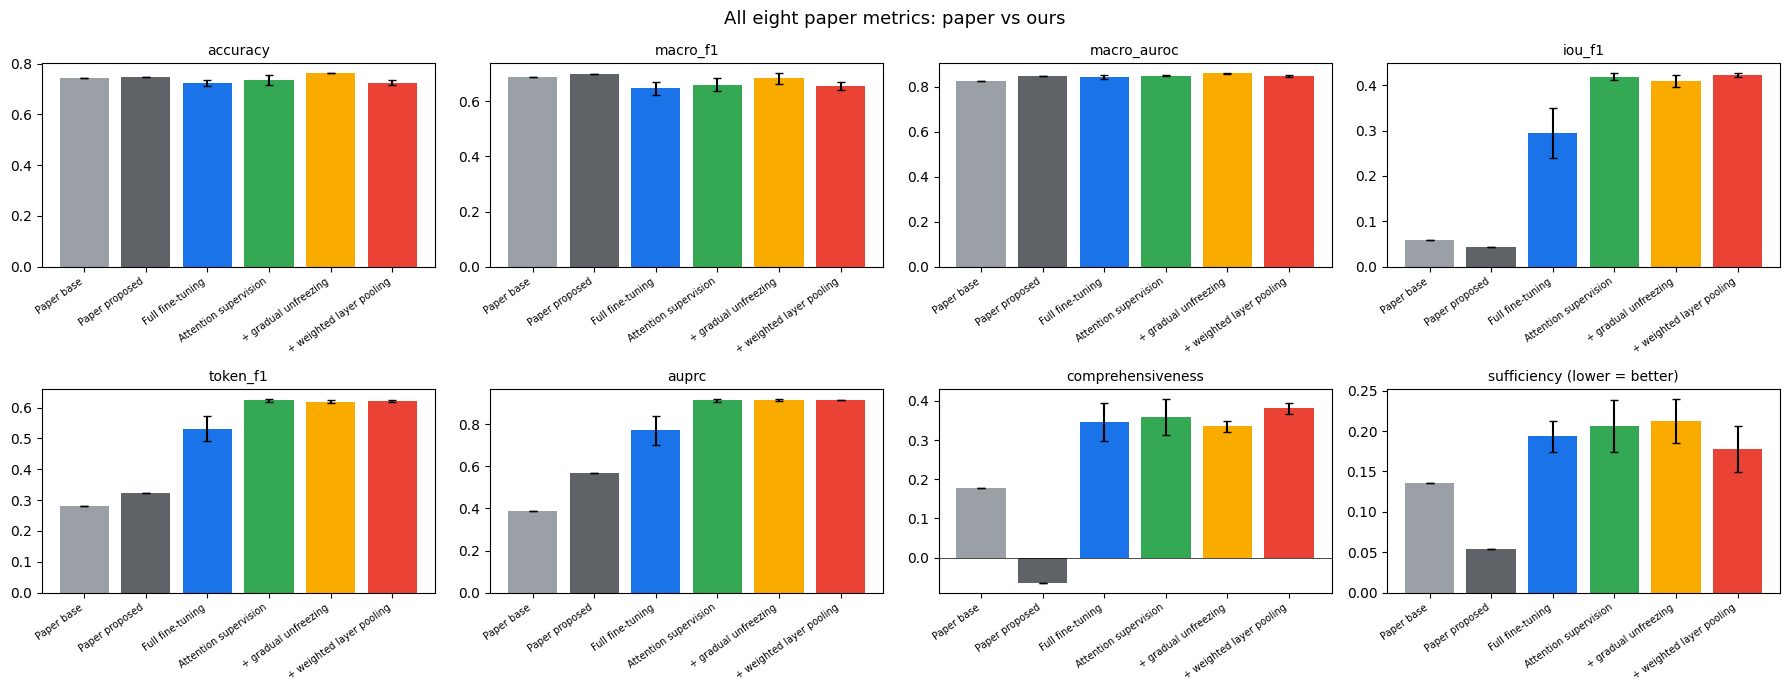


HOW TO READ THIS TABLE (be honest in the paper):
 * Classification: paper test set differs from ours (300 posts here), so gaps of ~3 points are within noise.
 * IOU-F1 / token-F1 / AUPRC: ours are scored on test posts that HAVE a human rationale, against the human HATE rationale.
 * Comprehensiveness / sufficiency: top-5 tokens masked with [MASK]; the paper's exact perturbation is not stated, so this column is the least comparable.
 * '+ gradual unfreezing' was singled out after looking at test results; the validation-selected variant is marked [val-selected]. Confirm on fresh seeds before claiming it.


In [17]:
from scipy.stats import ttest_rel

# ---------- paper values (Mamun et al., Table 2) ----------
PAPER = {
    "Paper baseline": dict(accuracy=0.7425, macro_f1=0.6883, macro_auroc=0.8264, iou_f1=0.0577, token_f1=0.2799,
                           auprc=0.3884, comprehensiveness=0.1789, sufficiency=0.1363),
    "Paper proposed": dict(accuracy=0.7492, macro_f1=0.6983, macro_auroc=0.8450, iou_f1=0.0429, token_f1=0.3232,
                           auprc=0.5667, comprehensiveness=-0.0655, sufficiency=0.0546),
}
# paper metric -> our column. IOU-F1 / token-F1 use the top-5 protocol (the paper protocol).
OURS_COL = {"accuracy": "accuracy", "macro_f1": "macro_f1", "macro_auroc": "macro_auroc",
            "iou_f1": "iou_f1_top5", "token_f1": "token_f1_top5", "auprc": "auprc",
            "comprehensiveness": "comprehensiveness", "sufficiency": "sufficiency"}
LOWER_IS_BETTER = {"sufficiency"}
METRICS = list(OURS_COL)

# ---------- 1) every variant, mean +/- std over seeds ----------
cols = ["val_macro_f1"] + [OURS_COL[m] for m in METRICS]
cols = [c for c in cols if c in results_df.columns]
agg = results_df.groupby("method", sort=False)[cols].agg(["mean", "std"])
summary = pd.DataFrame({c: agg[c]["mean"].map("{:.4f}".format) + " +/- " + agg[c]["std"].fillna(0).map("{:.4f}".format) for c in cols})
display(summary)
summary.to_csv(os.path.join(OUTPUT_DIR, "variant_comparison.csv"))

# ---------- 2) validation picks the variant; paired tests vs attention supervision ----------
rationale_runs = results_df[results_df.method != "Full fine-tuning"]
best_name = rationale_runs.groupby("method")["val_macro_f1"].mean().idxmax()
print("\nBest variant by mean VALIDATION macro-F1:", best_name)

base = "Attention supervision"
print(f"\nPaired comparison with '{base}' (test set, same seeds; few seeds = low power):")
for m in results_df.method.unique():
    if m in (base, "Full fine-tuning"): continue
    a = results_df[results_df.method == base].set_index("seed"); b = results_df[results_df.method == m].set_index("seed")
    common = sorted(set(a.index) & set(b.index))
    if len(common) < 2: continue
    line = f"  {m:<42}"
    for met in ["accuracy", "macro_f1", "macro_auroc", "auprc"]:
        d = (b.loc[common, met] - a.loc[common, met]).values
        p = ttest_rel(b.loc[common, met], a.loc[common, met]).pvalue if len(common) > 2 and d.std() > 0 else float("nan")
        line += f" | {met} {d.mean():+.4f} (p={p:.3f})"
    print(line)

# ---------- 3) ALL EIGHT paper metrics: paper vs ours ----------
ours = [n for n in ["Full fine-tuning", base, "+ gradual unfreezing", best_name] if n in set(results_df.method)]
ours = list(dict.fromkeys(ours))            # unique, keep order
rows, rows_num, lab2m = {}, {}, {}
for pname, vals in PAPER.items():
    rows[pname] = {m: f"{vals[m]:.4f}" for m in METRICS}; rows_num[pname] = dict(vals)
for nm in ours:
    sub = results_df[results_df.method == nm]
    tag = {"Full fine-tuning": "our baseline", base: "paper method on our data"}.get(nm, "")
    label = f"OURS: {nm}" + (f" ({tag})" if tag else "") + (" [val-selected]" if nm == best_name else "")
    lab2m[label] = nm
    rows[label] = {m: f"{sub[OURS_COL[m]].mean():.4f} +/- {sub[OURS_COL[m]].std():.4f}" for m in METRICS}
    rows_num[label] = {m: sub[OURS_COL[m]].mean() for m in METRICS}
full_tab = pd.DataFrame(rows).T[METRICS]
print("\n" + "=" * 100 + f"\nALL PAPER METRICS - paper vs ours (mean +/- std of {len(RUN_SEEDS)} seeds)\n" + "=" * 100)
display(full_tab)
full_tab.to_csv(os.path.join(OUTPUT_DIR, "final_vs_paper_all_metrics.csv"))

# difference to the paper's PROPOSED method, signed so that  +  always means "ours is better"
delta = {}
for lab, vals in rows_num.items():
    if lab.startswith("Paper"): continue
    delta[lab] = {m: (vals[m] - PAPER["Paper proposed"][m]) * (-1 if m in LOWER_IS_BETTER else 1) for m in METRICS}
delta_tab = pd.DataFrame(delta).T[METRICS]
print("\nDifference to 'Paper proposed' (+ = ours better; sufficiency sign flipped because lower is better):")
display(delta_tab.round(4))
delta_tab.round(4).to_csv(os.path.join(OUTPUT_DIR, "delta_vs_paper_proposed.csv"))
for lab in delta_tab.index:
    better = [m for m in METRICS if delta_tab.loc[lab, m] > 0]
    print(f"  {lab}: better than the paper on {len(better)}/8 -> {better}")

# ---------- 4) same table with the oracle-k protocol (k = gold rationale length) ----------
extra = [c for c in ["token_f1", "iou_f1"] if c in results_df.columns]
if extra:
    ex = results_df[results_df.method.isin(ours)].groupby("method", sort=False)[extra].agg(["mean", "std"])
    print("\nExtra: token-F1 / IOU-F1 with k = gold rationale length (easier protocol, NOT the paper's top-5):")
    display(pd.DataFrame({c: ex[c]["mean"].map("{:.4f}".format) + " +/- " + ex[c]["std"].fillna(0).map("{:.4f}".format) for c in extra}))
fcols = [c for c in ["comprehensiveness_20pct", "sufficiency_20pct"] if c in results_df.columns]
if fcols:
    fx = results_df[results_df.method.isin(ours)].groupby("method", sort=False)[fcols].agg(["mean", "std"])
    print("\nExtra: comprehensiveness / sufficiency with the top-20% of tokens masked:")
    display(pd.DataFrame({c: fx[c]["mean"].map("{:.4f}".format) + " +/- " + fx[c]["std"].fillna(0).map("{:.4f}".format) for c in fcols}))

# ---------- 5) chart: one panel per paper metric ----------
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
labels_all = list(rows_num)
palette = ["#9aa0a6", "#5f6368"] + ["#1a73e8", "#34a853", "#f9ab00", "#ea4335"][: len(ours)]
for ax, m in zip(axes.ravel(), METRICS):
    means = [rows_num[l][m] for l in labels_all]
    errs = [0 if l.startswith("Paper") else results_df[results_df.method == lab2m[l]][OURS_COL[m]].std() for l in labels_all]
    ax.bar(range(len(labels_all)), means, yerr=errs, color=palette[: len(labels_all)], capsize=3)
    ax.set_xticks(range(len(labels_all)))
    ax.set_xticklabels(["Paper base", "Paper proposed"] + [lab2m[l] for l in labels_all[2:]], fontsize=7, rotation=35, ha="right")
    ax.set_title(m + (" (lower = better)" if m in LOWER_IS_BETTER else ""), fontsize=10)
    ax.axhline(0, color="black", lw=0.5)
plt.suptitle("All eight paper metrics: paper vs ours", fontsize=13); plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "paper_vs_ours_all_metrics.png"), dpi=150); plt.show()

print("\nHOW TO READ THIS TABLE (be honest in the paper):")
print(" * Classification: paper test set differs from ours (300 posts here), so gaps of ~3 points are within noise.")
print(" * IOU-F1 / token-F1 / AUPRC: ours are scored on test posts that HAVE a human rationale, against the human HATE rationale.")
print(" * Comprehensiveness / sufficiency: top-5 tokens masked with [MASK]; the paper's exact perturbation is not stated, so this column is the least comparable.")
print(" * '+ gradual unfreezing' was singled out after looking at test results; the validation-selected variant is marked [val-selected]. Confirm on fresh seeds before claiming it.")


## 10. Faithfulness metrics: comprehensiveness and sufficiency

Computed for **every run** (function defined just before section 9) and included in the paper table of section 9b.
Take the model's own predicted class for the original post. Select the top-5 tokens by rationale attention (the HateXplain / paper protocol; a top-20% version is also stored as `*_20pct`). Special tokens are never selected. Then:
- **Comprehensiveness** = p(pred class) - p(pred class) after the selected tokens are replaced by `[MASK]`. Higher = the selected tokens matter.
- **Sufficiency** = p(pred class) - p(pred class) when only the selected tokens are kept. Lower = the selected tokens are enough.

Masking can create ungrammatical text, so state the perturbation in the paper and use the same one for every row.


In [18]:
# faithfulness_scores() is now defined BEFORE the experiments (section 9), because every run reports
# comprehensiveness and sufficiency. Nothing to run here.


## 11. Multi-seed evaluation and statistical reporting

Do not select the best random seed. Report mean ± standard deviation across seeds. Use identical seeds and splits for paired comparisons. For final claims, compute paired bootstrap confidence intervals on test examples and, where appropriate, McNemar's test for accuracy differences. Avoid repeated tuning on the test set.

In [19]:
# Aggregate repeated runs as mean ± standard deviation.
def summarize_results(results_frame):
    metric_cols=[c for c in [
        "accuracy","macro_f1","macro_auroc","token_f1","iou_f1","token_f1_top5","iou_f1_top5","auprc",
        "comprehensiveness","sufficiency","comprehensiveness_20pct","sufficiency_20pct"
    ] if c in results_frame.columns]
    agg=results_frame.groupby("method")[metric_cols].agg(["mean","std"])
    return agg

summary_table=summarize_results(results_df)
display(summary_table)
summary_table.to_csv(os.path.join(OUTPUT_DIR,"results_mean_std.csv"))
print("Saved:",os.path.join(OUTPUT_DIR,"results_mean_std.csv"))


accuracy            macro_f1  \
                                            mean       std      mean   
method                                                                 
+ LLRD                                  0.735556  0.012620  0.656440   
+ gradual unfreezing                    0.763333  0.000000  0.683643   
+ multi-sample dropout                  0.730000  0.024037  0.650156   
+ re-init top 2                         0.711111  0.018359  0.649925   
+ static freeze 3                       0.733333  0.015275  0.650319   
+ weighted layer pooling                0.724444  0.010184  0.655796   
Attention supervision                   0.735556  0.021430  0.660101   
COMBO (LLRD + re-init + pooling + MSD)  0.736667  0.013333  0.651742   
Full fine-tuning                        0.722222  0.011706  0.646747   
RAGF-BERT                               0.724444  0.022194  0.655312   

                                                 macro_auroc            \
                                             std        mean       std   
method                                                                   
+ LLRD                                  0.028419    0.851404  0.004191   
+ gradual unfreezing                    0.019133    0.858625  0.001743   
+ multi-sample dropout                  0.015719    0.840654  0.008110   
+ re-init top 2                         0.007095    0.839284  0.005594   
+ static freeze 3                       0.017866    0.851085  0.003592   
+ weighted layer pooling                0.013307    0.847042  0.003425   
Attention supervision                   0.023420    0.849235  0.002565   
COMBO (LLRD + re-init + pooling + MSD)  0.005970    0.843100  0.008225   
Full fine-tuning                        0.023708    0.842576  0.009190   
RAGF-BERT                               0.009943    0.846846  0.003986   

                                        token_f1              iou_f1  \
                                            mean       std      mean   
method                                                                 
+ LLRD                                  0.878187  0.003846  0.772322   
+ gradual unfreezing                    0.873463  0.007002  0.755492   
+ multi-sample dropout                  0.881554  0.003249  0.780085   
+ re-init top 2                         0.892775  0.004059  0.792716   
+ static freeze 3                       0.881453  0.006529  0.772246   
+ weighted layer pooling                0.877778  0.000920  0.772611   
Attention supervision                   0.873567  0.007693  0.760352   
COMBO (LLRD + re-init + pooling + MSD)  0.883272  0.007836  0.775727   
Full fine-tuning                        0.722108  0.063331  0.505257   
RAGF-BERT                               0.873669  0.007520  0.771224   

                                                  ...     auprc            \
                                             std  ...      mean       std   
method                                            ...                       
+ LLRD                                  0.007693  ...  0.918117  0.005653   
+ gradual unfreezing                    0.019111  ...  0.914242  0.005060   
+ multi-sample dropout                  0.007630  ...  0.919358  0.003845   
+ re-init top 2                         0.005776  ...  0.926175  0.004402   
+ static freeze 3                       0.010236  ...  0.917861  0.007033   
+ weighted layer pooling                0.005602  ...  0.914299  0.000976   
Attention supervision                   0.002263  ...  0.913548  0.006834   
COMBO (LLRD + re-init + pooling + MSD)  0.009012  ...  0.918081  0.003544   
Full fine-tuning                        0.093355  ...  0.770782  0.069835   
RAGF-BERT                               0.004764  ...  0.912765  0.002995   

                                       comprehensiveness            \
                                                    mean       std   
method                                                       

Saved: /content/ragf_bert/results_mean_std.csv


## 12. Visualizations and final report

Generate:
- confusion matrices;
- per-class precision/recall/F1;
- metric comparison chart;
- layer-freezing timeline;
- layer-wise gradient/importance heatmaps;
- training/validation curves.

A valid research conclusion must distinguish:
1. improvement over the reproduced baseline;
2. improvement over the paper's published numbers;
3. improvement on the combined dataset;
4. cross-source generalization.

Only (1) and (3) can be directly established from the experiment using the supplied data and split. A direct claim against the paper's published test score requires the same original test examples and evaluation implementation.

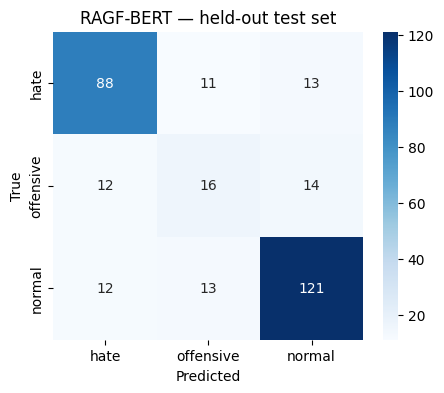

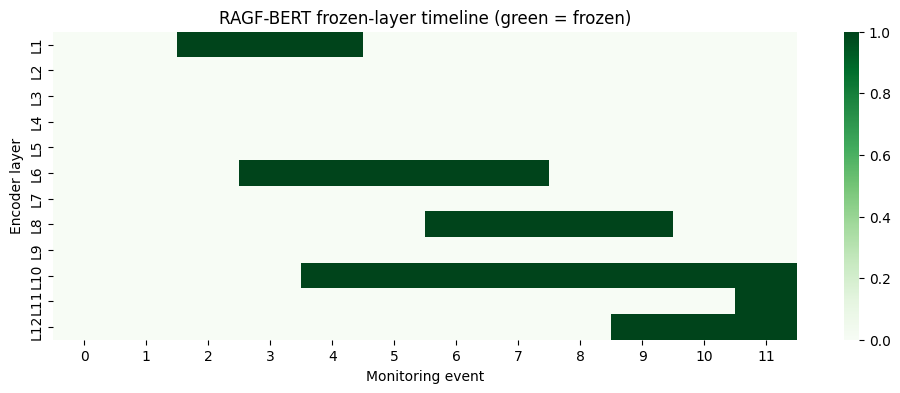

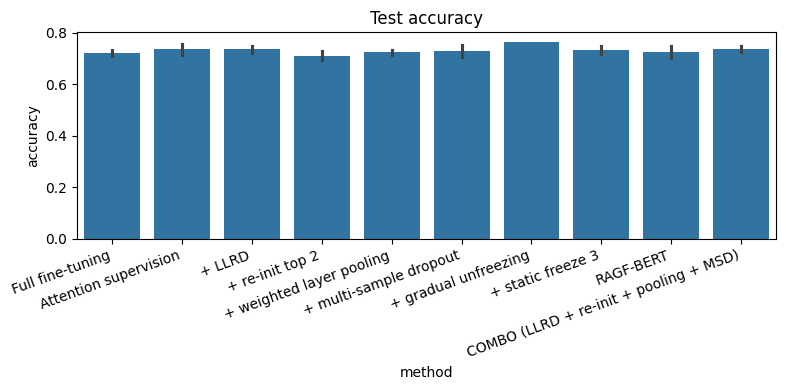

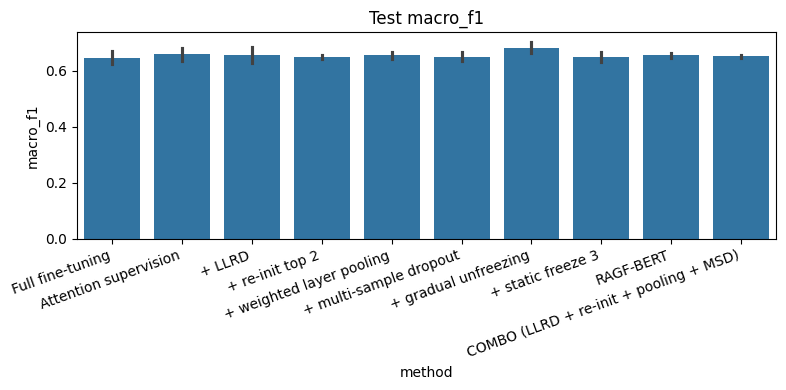

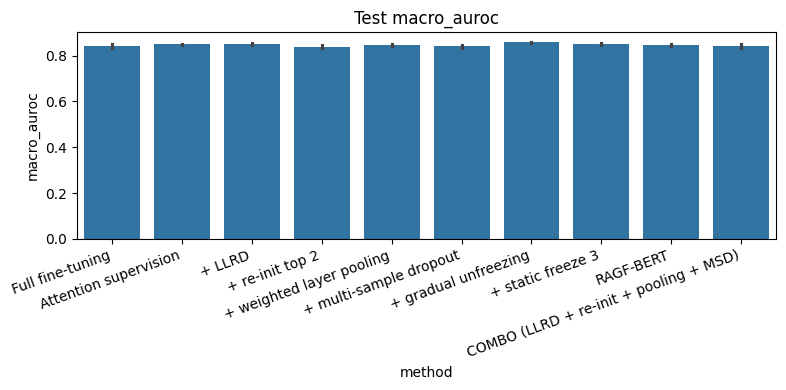

RAGF faithfulness: {'comprehensiveness': 0.37174627917973946, 'sufficiency': 0.22521745964884757, 'comprehensiveness_20pct': 0.3475893808350277, 'sufficiency_20pct': 0.2715149655068914, 'n_examples': 300}


In [20]:
def plot_confusion(y, probs, title="Confusion matrix"):
    pred=probs.argmax(1)
    cm=confusion_matrix(y,pred,labels=[0,1,2])
    plt.figure(figsize=(5,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",
                xticklabels=[ID2LABEL[i] for i in range(3)],
                yticklabels=[ID2LABEL[i] for i in range(3)])
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(title); plt.show()

def plot_controller_history(controller):
    if controller is None or not controller.history:
        print("No controller history."); return
    hist=controller.history
    mat=np.zeros((len(hist),12))
    for t,h in enumerate(hist):
        mat[t,h["frozen_layers"]]=1
    plt.figure(figsize=(12,4))
    sns.heatmap(mat.T,cmap="Greens",cbar=True,
                yticklabels=[f"L{i+1}" for i in range(12)])
    plt.xlabel("Monitoring event"); plt.ylabel("Encoder layer")
    plt.title("RAGF-BERT frozen-layer timeline (green = frozen)")
    plt.show()

# Display confusion matrix and freezing timeline for the proposed method.
if "RAGF-BERT" in trained_models:
    ragf_model,ragf_outputs,ragf_controller=trained_models["RAGF-BERT"]
    y,probs=ragf_outputs[0],ragf_outputs[1]
    plot_confusion(y,probs,"RAGF-BERT — held-out test set")
    plot_controller_history(ragf_controller)

# Compare classification metrics across the actual test runs.
if len(results_df):
    for metric in ["accuracy","macro_f1","macro_auroc"]:
        if metric in results_df:
            plt.figure(figsize=(8,4))
            sns.barplot(data=results_df,x="method",y=metric,errorbar="sd")
            plt.xticks(rotation=20,ha="right")
            plt.title(f"Test {metric}")
            plt.tight_layout()
            plt.show()

# Optional faithfulness scores on a sample of the held-out test data.
if "RAGF-BERT" in trained_models:
    print("RAGF faithfulness:",faithfulness_scores(ragf_model,test_df,max_examples=300))


# If gold rationales are absent, show illustrative model-generated token explanations.
# These are not human-validated rationales and must not be reported as plausibility scores.
if "RAGF-BERT" not in trained_models and "Adaptive classification" in trained_models:
    explain_model = trained_models["Adaptive classification"][0]
    @torch.no_grad()
    def show_token_explanations(model, texts, n=5):
        model.eval()
        rows = []
        for text_value in list(texts)[:n]:
            enc = tokenizer(str(text_value), return_tensors="pt",
                            truncation=True, max_length=MAX_LENGTH)
            ids = enc["input_ids"].to(DEVICE)
            mask = enc["attention_mask"].to(DEVICE)
            logits, token_scores = model(ids, mask)
            probs = logits.softmax(-1)[0].cpu().numpy()
            toks = tokenizer.convert_ids_to_tokens(ids[0].cpu().tolist())
            special = tokenizer.get_special_tokens_mask(
                ids[0].cpu().tolist(), already_has_special_tokens=True
            )
            scores = token_scores[0].cpu().numpy()
            valid_idx = [j for j, flag in enumerate(special) if not flag and mask[0,j].item() == 1]
            top = sorted(valid_idx, key=lambda j: scores[j], reverse=True)[:5]
            rows.append({
                "text": str(text_value),
                "predicted_label": ID2LABEL[int(np.argmax(probs))],
                "confidence": float(np.max(probs)),
                "top_tokens": " ".join(toks[j] for j in top),
            })
        return pd.DataFrame(rows)

    display(show_token_explanations(explain_model, test_df["text"].tolist(), n=5))


## 13. Research checklist before publication

- [ ] Confirm the exact HateXplain release, label mapping, rationale format and split.
- [ ] Verify user's CSV labels and rationale availability; do not invent rationale masks.
- [ ] Remove duplicate texts before splitting; consider near-duplicate grouping.
- [ ] Reproduce the original method as closely as available code permits.
- [ ] Compare static freezing, gradual unfreezing and dynamic policies.
- [ ] Run five seeds and report mean ± standard deviation.
- [ ] Report per-class scores and class imbalance.
- [ ] Report all eight paper metrics with consistent definitions.
- [ ] Validate comprehensiveness/sufficiency perturbation choices.
- [ ] Report GPU time, peak memory and frozen-layer schedule.
- [ ] Use paired confidence intervals and avoid test-set tuning.
- [ ] Do not claim the private 3,199-example paper dataset was reproduced unless it was actually supplied.
- [ ] Do not claim novelty as "first" without a systematic literature review.

**Expected output files:** checkpoints (`.pt`), experiment histories (`.csv`), controller traces (`.json`), confusion matrices and final metric tables under `/kaggle/working/ragf_bert/`.

## 14. Export and interpret your results

After the experiment runner finishes, these files are saved in `/content/ragf_bert/`:

- `test_results.csv` — test metrics for each method and seed.
- `results_mean_std.csv` — mean and standard deviation across seeds.
- `*_history.csv` — per-epoch validation history.
- `*_best.pt` — selected model checkpoints.
- `*_controller.json` — adaptive freezing trace.

To download the main results from Colab:
```python
from google.colab import files
files.download('/content/ragf_bert/test_results.csv')
files.download('/content/ragf_bert/results_mean_std.csv')
```

**Interpretation:** higher accuracy, macro-F1, AUROC, token-F1, IOU-F1 and AUPRC are better. Higher comprehensiveness is better; lower sufficiency is better. The notebook's faithfulness scores are an approximate perturbation evaluation and should be described with the exact masking protocol above.

The paper's published Table 2 is a reference, not a matched baseline: it reports accuracy 0.7425/0.7492 and macro-F1 0.6883/0.6983 for baseline/proposed, respectively. Do not claim a direct improvement over those values unless you reproduce the same dataset, split, preprocessing and evaluation protocol. The results generated here are your measured results on your own held-out test split.


If no human token-level rationale annotations are found, the notebook automatically runs valid classification experiments instead of stopping with an error. It also prints sample model-generated token explanations. Those explanations are qualitative only; token-F1, IOU-F1 and AUPRC against human rationales remain unavailable until gold rationales are supplied.

- `run_status.json` — records whether gold rationale supervision was available and which claims this run supports.
